# GLCMaeV8 Training on Welding Robot Data

End-to-end training pipeline for `GLCMaeV8` — Asymmetric MAE with Dual-Stream CNN Encoder + Context Embedding.

**Architecture highlights (vs GLCReconV8):**
- Masked training (mask_ratio=0.45) → encoder only sees 55 % of tokens per forward pass
- `MaskToken` (learnable [MASK] parameter) fills in masked positions at unshuffle time
- `LightDecoder` (2-layer MLP, no Tanh) replaces full CNNDecoder
- Loss: MSE **on masked positions only** → forces encoder to learn global representations
- Val loss also uses masked forward → directly comparable scale to train loss
- CNN patch encoders (global + local streams) + `ContextEmbedding(robot, program)` preserved

**Pipeline:**
1. Load train CSV + val CSV → group by `cycle_id`, build codebooks
2. Create `RawWindowDataset` with robot/program indices
3. Initialize `GLCMaeV8` with context embedding
4. Train with `GLCMaeV8Trainer` (warmup + cosine LR, best-ckpt tracking)
5. Visualize training curves
6. Evaluate AUROC with synthetic anomaly injection
7. Save checkpoint

In [ ]:
# %% Imports
import sys
import csv
import json
import math
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt

# Add anomaly-detection/src to path so import src.anomaly_detection resolves
project_root = Path.cwd().parent.parent.resolve()
src_path = project_root / "anomaly-detection" / "src"
print(src_path)
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from src.anomaly_detection.utils import set_random_seed
set_random_seed(42)

from src.anomaly_detection.models import create_model, SupportedAnomalyDetectionModels
from src.anomaly_detection.models.glc_mae_v8 import GLCMaeV8, GLCMaeV8Config
from src.anomaly_detection.training.glc_mae_v8_trainer import (
    GLCMaeV8Trainer,
    GLCMaeV8Evaluator,
)
from src.anomaly_detection.training.datasets import RawWindowDataset

print("All imports OK")
print(f"PyTorch {torch.__version__}, CUDA available: {torch.cuda.is_available()}")

/home/trietlm/TED-Hackathon-Agent
All imports OK
PyTorch 2.12.0+cu130, CUDA available: True


## 1. Load Train + Validation Data

Two separate CSV files (generated by `Sprint16-Generate-Test-Data.ipynb`).
Group by `cycle_id` into macro-windows (seq_len=240, stride=80).
Build robot/program codebooks from **train set only** (extended for val/test unseen codes).

In [2]:
DATA_DIR = project_root / "data" / "generated_sprint18b"
TRAIN_CSV = DATA_DIR / "train_welding_robot.csv"
VAL_CSV   = DATA_DIR / "val_welding_robot.csv"

# Fallback to project_root/data/
if not TRAIN_CSV.exists():
    DATA_DIR = project_root / "data"
    TRAIN_CSV = DATA_DIR / "train_welding_robot.csv"
    VAL_CSV   = DATA_DIR / "val_welding_robot.csv"

print(f"Train CSV: {TRAIN_CSV}  (exists={TRAIN_CSV.exists()})")
print(f"Val CSV:   {VAL_CSV}  (exists={VAL_CSV.exists()})")

SENSOR_COLS = ["wire_feed_speed_mm_min", "wire_temperature_c", "welding_current_a"]
SEQ_LEN = 256
STRIDE  = 64
NUM_SENSORS = 3

def load_csv_to_windows(
    csv_path,
    seq_len=SEQ_LEN,
    stride=STRIDE,
    robot_to_idx=None,
    program_to_idx=None,
):
    """Load CSV -> group by cycle_id -> build macro-windows [N, C, T].

    If robot_to_idx / program_to_idx are provided, they are used as-is and
    extended for any unseen codes.  Pass them from a prior call to share the
    same vocabulary across train / val / test sets.
    """
    if not csv_path.exists():
        print(f"  WARNING: {csv_path} not found, returning empty.")
        empty = (
            np.zeros((0, NUM_SENSORS, seq_len), dtype=np.float32),
            np.zeros(0, dtype=np.int64),
            np.zeros(0, dtype=np.int64),
            robot_to_idx or {},
            program_to_idx or {},
        )
        return empty

    with open(csv_path, "r") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
    print(f"  Loaded {len(rows):,} rows from {csv_path.name}")

    groups = defaultdict(list)
    for r in rows:
        groups[int(r["cycle_id"])].append(r)
    print(f"  Unique cycle_ids: {len(groups)}")

    # Build or extend codebooks
    if robot_to_idx is None:
        all_robot_codes = sorted(set(str(r["robot_code"]) for r in rows))
        robot_to_idx = {code: i for i, code in enumerate(all_robot_codes)}
    else:
        for r in rows:
            rc = str(r["robot_code"])
            if rc not in robot_to_idx:
                robot_to_idx[rc] = len(robot_to_idx)

    if program_to_idx is None:
        all_program_nums = sorted(set(str(r["program_number"]) for r in rows))
        program_to_idx = {pn: i for i, pn in enumerate(all_program_nums)}
    else:
        for r in rows:
            pn = str(r["program_number"])
            if pn not in program_to_idx:
                program_to_idx[pn] = len(program_to_idx)

    windows_list, robot_list, program_list = [], [], []

    for cid, group_rows in groups.items():
        group_rows.sort(key=lambda x: int(x["serial_number"]))
        file_arr = np.array(
            [[float(r[col]) for col in SENSOR_COLS] for r in group_rows],
            dtype=np.float32,
        ).T  # [C, T]
        T = file_arr.shape[1]
        rc = str(group_rows[0]["robot_code"])
        pn = str(group_rows[0]["program_number"])

        if T >= seq_len:
            for start in range(0, T - seq_len + 1, stride):
                windows_list.append(file_arr[:, start:start + seq_len])
                robot_list.append(robot_to_idx[rc])
                program_list.append(program_to_idx[pn])
            # tail padding: always added when SEQ_LEN > STRIDE
            tail_start = ((T - seq_len) // stride) * stride + stride
            if tail_start < T:
                tail = file_arr[:, tail_start:]
                pad  = np.zeros((NUM_SENSORS, seq_len - tail.shape[1]), dtype=np.float32)
                windows_list.append(np.hstack([tail, pad]))
                robot_list.append(robot_to_idx[rc])
                program_list.append(program_to_idx[pn])
        else:
            pad = np.zeros((NUM_SENSORS, seq_len - T), dtype=np.float32)
            windows_list.append(np.hstack([file_arr, pad]))
            robot_list.append(robot_to_idx[rc])
            program_list.append(program_to_idx[pn])

    windows_arr = np.stack(windows_list, axis=0)   # [N, C, T]
    robot_arr   = np.array(robot_list,   dtype=np.int64)
    program_arr = np.array(program_list, dtype=np.int64)

    assert len(windows_arr) == len(robot_arr) == len(program_arr), (
        f"Length mismatch: windows={len(windows_arr)}, "
        f"robot={len(robot_arr)}, program={len(program_arr)}"
    )
    print(f"  Windows: {windows_arr.shape}")
    return windows_arr, robot_arr, program_arr, robot_to_idx, program_to_idx

print("\n--- Loading TRAIN data ---")
(
    train_windows, train_robots, train_programs,
    robot_to_idx, program_to_idx,
) = load_csv_to_windows(TRAIN_CSV)

print("\n--- Loading VALIDATION data ---")
# Pass train codebooks so val indices are in the same vocabulary
(
    val_windows, val_robots, val_programs,
    robot_to_idx, program_to_idx,
) = load_csv_to_windows(VAL_CSV, robot_to_idx=robot_to_idx, program_to_idx=program_to_idx)

NUM_ROBOTS   = len(robot_to_idx)
NUM_PROGRAMS = len(program_to_idx)

print(f"\nCombined codebooks: {NUM_ROBOTS} robots, {NUM_PROGRAMS} programs")
print(f"Train windows: {len(train_windows)}, Val windows: {len(val_windows)}")


Train CSV: /home/trietlm/TED-Hackathon-Agent/data/generated_sprint18b/train_welding_robot.csv  (exists=True)
Val CSV:   /home/trietlm/TED-Hackathon-Agent/data/generated_sprint18b/val_welding_robot.csv  (exists=True)

--- Loading TRAIN data ---
  Loaded 32,769,024 rows from train_welding_robot.csv
  Unique cycle_ids: 64002
  Windows: (384012, 3, 256)

--- Loading VALIDATION data ---
  Loaded 8,139,264 rows from val_welding_robot.csv
  Unique cycle_ids: 15897
  Windows: (95382, 3, 256)

Combined codebooks: 4 robots, 16 programs
Train windows: 384012, Val windows: 95382


## 2. Create Dataset & DataLoader

In [3]:
BATCH_SIZE = 64

train_dataset = RawWindowDataset(
    windows=train_windows,
    robot_indices=train_robots,
    program_indices=train_programs,
)
val_dataset = RawWindowDataset(
    windows=val_windows,
    robot_indices=val_robots,
    program_indices=val_programs,
)

train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
    num_workers=0, pin_memory=False,
)
val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=False,
)

print(f"Train windows:  {len(train_dataset)}")
print(f"Val windows:    {len(val_dataset)}")
print(f"Batches/epoch:  train={len(train_loader)}, val={len(val_loader)}")
print(f"Sample keys:    {list(train_dataset[0].keys())}")
print(f"  input shape:  {train_dataset[0]['input'].shape}")
print(f"  robot_idx:    {train_dataset[0]['robot_idx'].item()}")
print(f"  program_idx:  {train_dataset[0]['program_idx'].item()}")

Train windows:  384012
Val windows:    95382
Batches/epoch:  train=6000, val=1491
Sample keys:    ['input', 'robot_idx', 'program_idx']
  input shape:  torch.Size([3, 256])
  robot_idx:    0
  program_idx:  14


## 3. Initialize GLCMaeV8 Model

Key config:
- `num_sensors=3`, `seq_len=240`
- `num_robots` / `num_programs` from loaded codebooks → enables `ContextEmbedding`
- `use_context_embeddings=True`
- `mask_ratio=0.45` → 45 % of tokens masked during training
- `patch_size=32`, `patch_stride=16` → 14 patches per sensor, 42 total tokens

In [4]:
config = GLCMaeV8Config(
    num_sensors=NUM_SENSORS,
    seq_len=SEQ_LEN,
    num_robots=8,
    num_programs=128,
    patch_size=32,
    patch_stride=16,
    d_model=128,
    transformer_layers=4,
    transformer_heads=4,
    ffn_dim=512,
    dropout=0.2,
    mask_ratio=0.4,
    use_context_embeddings=True,
)

model = create_model(SupportedAnomalyDetectionModels.GLC_MAE_V8, config)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model:           {model.name}")
print(f"Total params:    {total_params:,}")
print(f"Trainable:       {trainable_params:,}")
print(f"num_patches:     {model.num_patches}  (per sensor)")
print(f"num_tokens:      {model.num_tokens}  (C * P = {NUM_SENSORS} * {model.num_patches})")
print(f"d_model:         {model.d_model}  (d_half={model.d_half} per stream)")
print(f"mask_ratio:      {model.mask_ratio}")

Model:           GLCMaeV8
Total params:    968,375
Trainable:       968,375
num_patches:     15  (per sensor)
num_tokens:      45  (C * P = 3 * 15)
d_model:         128  (d_half=64 per stream)
mask_ratio:      0.4


/home/trietlm/TED-Hackathon-Agent/backend/app/anomaly_detection/layers/attention.py:97: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


## 4. Smoke Test — Forward Pass

Verify forward pass and loss computation before full training.

In [5]:
model.eval()
with torch.no_grad():
    dummy_batch = {
        "input":       torch.randn(2, NUM_SENSORS, SEQ_LEN),
        "robot_idx":   torch.zeros(2, dtype=torch.long),
        "program_idx": torch.zeros(2, dtype=torch.long),
    }
    out = model.compute_loss(dummy_batch)
    heatmap = model.compute_heatmap(dummy_batch)

print(f"Smoke test PASSED")
print(f"  loss:    {out['loss'].item():.6f}  (scalar)")
print(f"  recon_error shape: {out['recon_error'].shape}  (expected [2, {model.num_tokens}])")
print(f"  heatmap shape:     {heatmap.shape}  (expected [2, {NUM_SENSORS}, {model.num_patches}])")

Smoke test PASSED
  loss:    1.113682  (scalar)
  recon_error shape: torch.Size([2, 45])  (expected [2, 45])
  heatmap shape:     torch.Size([2, 3, 15])  (expected [2, 3, 15])


## 5. Initialize Trainer & Train

- Linear warmup for first 5 epochs, then CosineAnnealing to `lr * 0.01`
- **Both train and val loss use the masked MAE forward** → no distribution mismatch
- Best checkpoint (lowest val_loss) stored automatically in `trainer.best_state_dict`

In [6]:
EPOCHS        = 100
LR            = 1e-3
WARMUP_EPOCHS = 25

trainer = GLCMaeV8Trainer(
    model=model,
    lr=LR,
    weight_decay=1e-5,
    clip_grad_norm=1.0,
    warmup_epochs=WARMUP_EPOCHS,
    total_epochs=EPOCHS,
    min_lr_ratio=0.01,
)

print(f"Device:      {trainer.device}")
print(f"Epochs:      {EPOCHS}  (warmup={WARMUP_EPOCHS}, cosine={EPOCHS - WARMUP_EPOCHS})")
print(f"LR:          {LR:.1e} → {LR * 0.01:.1e}  (peak → floor)")
print("\nStarting training...")

history = trainer.train(
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    lr=LR,
    save_best=True,
)

print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)
print(f"  train_loss:  {history['loss'][0]:.4f} → {history['loss'][-1]:.4f}")
print(f"  val_loss:    {history['val_loss'][0]:.4f} → {history['val_loss'][-1]:.4f}")
print(f"  best epoch:  {trainer.best_epoch + 1}  (val_loss={trainer.best_val_loss:.4f})")
print("=" * 60)

Device:      cuda
Epochs:      100  (warmup=25, cosine=75)
LR:          1.0e-03 → 1.0e-05  (peak → floor)

Starting training...


Epochs:   0%|          | 0/100 [00:00<?, ?it/s]

Train E1:   0%|          | 0/6000 [00:00<?, ?it/s]

Val:   0%|          | 0/1491 [00:00<?, ?it/s]

Train E2:   0%|          | 0/6000 [00:00<?, ?it/s]

...

Train E99:   0%|          | 0/6000 [00:00<?, ?it/s]

Val:   0%|          | 0/1491 [00:00<?, ?it/s]

Train E100:   0%|          | 0/6000 [00:00<?, ?it/s]

Val:   0%|          | 0/1491 [00:00<?, ?it/s]


TRAINING COMPLETE
  train_loss:  0.4218 → 0.1577
  val_loss:    0.3526 → 0.1554
  best epoch:  93  (val_loss=0.1544)


## 6. Visualize Training Curves

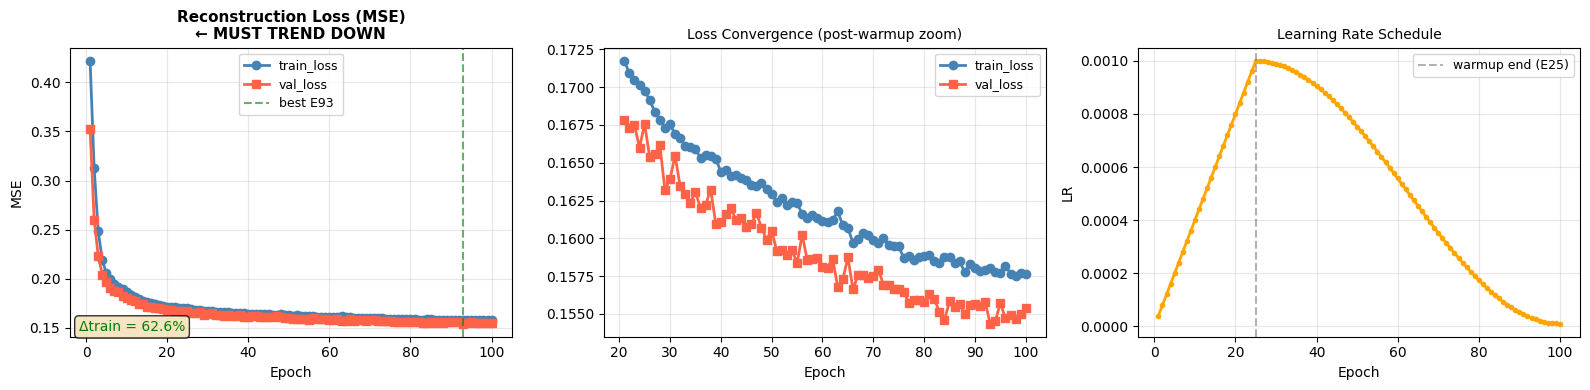

TRAINING HEALTH REPORT
  train_loss:  0.4218 → 0.1577  (+62.6%)
  val_loss:    0.3526 → 0.1554
  gap (val-train): -0.0022  (near 0 = no mismatch)
  best epoch:  93  val=0.1544


In [12]:
epochs_range = range(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (0): train vs val loss
ax = axes[0]
ax.plot(epochs_range, history["loss"],     marker="o", lw=2, color="steelblue", label="train_loss")
ax.plot(epochs_range, history["val_loss"], marker="s", lw=2, color="tomato",    label="val_loss")
ax.axvline(x=trainer.best_epoch + 1, color="green", ls="--", alpha=0.6,
           label=f"best E{trainer.best_epoch + 1}")
improvement = (history["loss"][0] - history["loss"][-1]) / max(history["loss"][0], 1e-8) * 100
ax.text(0.02, 0.02, f"Δtrain = {improvement:.1f}%", transform=ax.transAxes,
        fontsize=10, color="green" if improvement > 5 else "red",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))
ax.set_title("Reconstruction Loss (MSE)\n← MUST TREND DOWN", fontsize=11, fontweight="bold")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# (1): train vs val loss zoom (last 80%)
ax = axes[1]
start_ep = max(0, len(history["loss"]) // 5)
ax.plot(list(epochs_range)[start_ep:], history["loss"][start_ep:],
        marker="o", lw=2, color="steelblue", label="train_loss")
ax.plot(list(epochs_range)[start_ep:], history["val_loss"][start_ep:],
        marker="s", lw=2, color="tomato",    label="val_loss")
ax.set_title("Loss Convergence (post-warmup zoom)", fontsize=10)
ax.set_xlabel("Epoch"); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# (2): LR schedule
ax = axes[2]
ax.plot(epochs_range, history["lr"], marker=".", color="orange", lw=2)
ax.axvline(x=WARMUP_EPOCHS, color="gray", ls="--", alpha=0.6, label=f"warmup end (E{WARMUP_EPOCHS})")
ax.set_title("Learning Rate Schedule", fontsize=10)
ax.set_xlabel("Epoch"); ax.set_ylabel("LR")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("=" * 55)
print("TRAINING HEALTH REPORT")
print("=" * 55)
gap = history["val_loss"][-1] - history["loss"][-1]
print(f"  train_loss:  {history['loss'][0]:.4f} → {history['loss'][-1]:.4f}  ({improvement:+.1f}%)")
print(f"  val_loss:    {history['val_loss'][0]:.4f} → {history['val_loss'][-1]:.4f}")
print(f"  gap (val-train): {gap:.4f}  (near 0 = no mismatch)")
print(f"  best epoch:  {trainer.best_epoch + 1}  val={trainer.best_val_loss:.4f}")
print("=" * 55)

## 7. Restore Best Checkpoint & Evaluate AUROC

Inject synthetic anomalies (spike, oscillation, flatline) into val windows
and compare reconstruction error distributions.

Scoring uses **full inference forward** (`_forward_impl`, no masking) → deterministic.

In [13]:
# Restore best weights
trainer.restore_best()
print(f"Restored best checkpoint from epoch {trainer.best_epoch + 1}")

device_str = str(trainer.device)
N_EVAL = min(len(val_windows), 200)
sensor_stds = val_windows.std(axis=(0, 2))
print(f"Per-sensor global std (val set): {sensor_stds}")

# Build normal batches from val set
normal_batches = [
    {
        "input":       torch.tensor(val_windows[i], dtype=torch.float32).unsqueeze(0),
        "robot_idx":   torch.tensor([val_robots[i]],   dtype=torch.long),
        "program_idx": torch.tensor([val_programs[i]], dtype=torch.long),
    }
    for i in range(N_EVAL)
]

# Build anomaly batches with synthetic injection
anomaly_batches = GLCMaeV8Evaluator.build_anomaly_batches(
    normal_windows=val_windows[:N_EVAL],
    robot_indices=val_robots[:N_EVAL],
    program_indices=val_programs[:N_EVAL],
    sensor_stds=sensor_stds,
    patch_size=model.patch_size,
    seed=42,
)

print(f"Normal files:  {len(normal_batches)}")
print(f"Anomaly files: {len(anomaly_batches)}")

# Evaluate
evaluator = GLCMaeV8Evaluator(model, device=device_str)
result = evaluator.evaluate(normal_batches, anomaly_batches)

print(f"\n{'='*45}")
print(f"AUROC:  {result.auroc:.4f}")
print(f"AUPRC:  {result.auprc:.4f}")
print(f"Threshold (MAD): {result.threshold:.6f}")
print(f"Samples: {result.num_normal} normal, {result.num_anomaly} anomaly")
print(f"{'='*45}")
if result.auroc > 0.7:
    print("Good separation — anomaly signal present.")
elif result.auroc > 0.5:
    print("Weak separation — model detects some anomalies.")
else:
    print("Near-random — check training convergence.")

Restored best checkpoint from epoch 93
Per-sensor global std (val set): [77.495186   7.5579696  3.7402897]
Normal files:  200
Anomaly files: 200

AUROC:  0.7859
AUPRC:  0.7702
Threshold (MAD): 3.297765
Samples: 200 normal, 200 anomaly
Good separation — anomaly signal present.


/tmp/ipykernel_964458/2394688374.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([normal_arr, anomaly_arr], labels=["Normal", "Anomaly"], patch_artist=True,


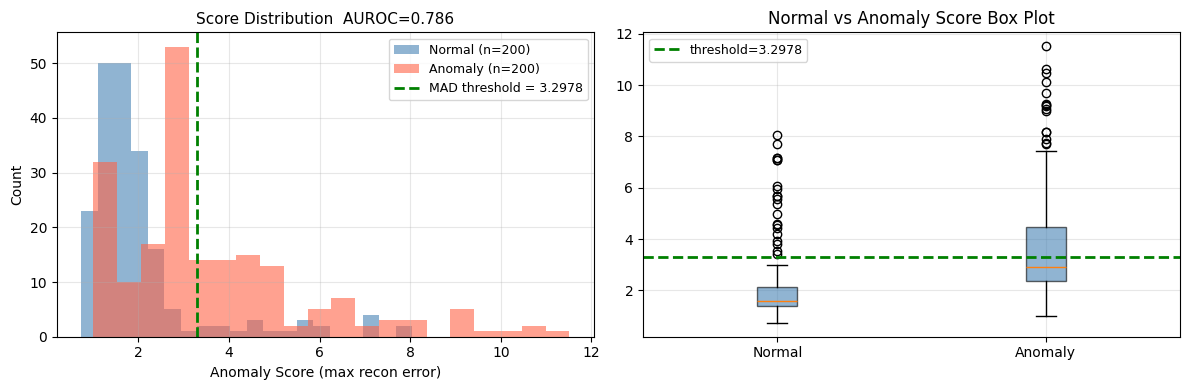

In [14]:
# Score distribution visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

normal_arr  = np.array(result.normal_scores)
anomaly_arr = np.array(result.anomaly_scores)

ax = axes[0]
ax.hist(normal_arr,  bins=20, alpha=0.6, color="steelblue", label=f"Normal (n={len(normal_arr)})")
ax.hist(anomaly_arr, bins=20, alpha=0.6, color="tomato",    label=f"Anomaly (n={len(anomaly_arr)})")
ax.axvline(x=result.threshold, color="green", ls="--", lw=2,
           label=f"MAD threshold = {result.threshold:.4f}")
ax.set_title(f"Score Distribution  AUROC={result.auroc:.3f}", fontsize=11)
ax.set_xlabel("Anomaly Score (max recon error)")
ax.set_ylabel("Count")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.boxplot([normal_arr, anomaly_arr], labels=["Normal", "Anomaly"], patch_artist=True,
           boxprops=dict(facecolor="steelblue", alpha=0.6))
all_scores = list(normal_arr) + list(anomaly_arr)
ax.axhline(y=result.threshold, color="green", ls="--", lw=2, label=f"threshold={result.threshold:.4f}")
ax.set_title("Normal vs Anomaly Score Box Plot")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Visualize Reconstruction — Sanity Check

Verify that the model learned to reconstruct the GlobalRevIN-normalized patches.

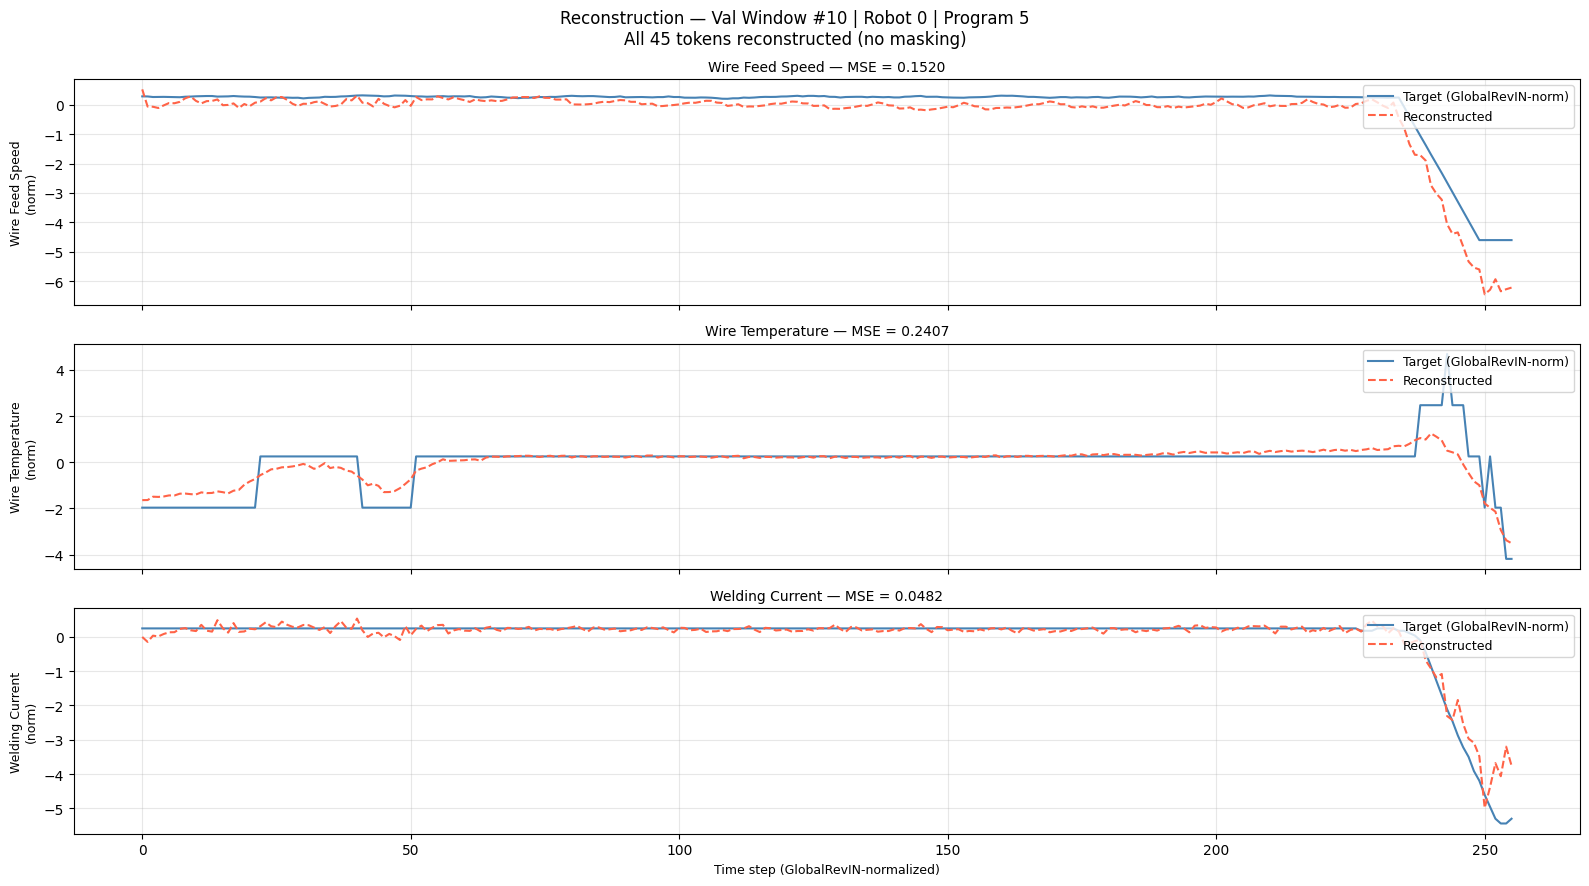

Overall MSE:  0.1470
Target var:   0.6060
Pred var:     0.5689
Var ratio:    0.939  (near 1.0 = good, near 0 = collapsed)


In [15]:
WINDOW_IDX   = min(10, len(val_windows) - 1)
SENSOR_NAMES = ["Wire Feed Speed", "Wire Temperature", "Welding Current"]

window_np  = val_windows[WINDOW_IDX]
robot_i    = int(val_robots[WINDOW_IDX])
program_i  = int(val_programs[WINDOW_IDX])

x_t       = torch.tensor(window_np, dtype=torch.float32).unsqueeze(0).to('cuda')
robot_t   = torch.tensor([robot_i],   dtype=torch.long).to('cuda')
program_t = torch.tensor([program_i], dtype=torch.long).to('cuda')

model.eval()
with torch.no_grad():
    out = model._forward_impl(x_t, robot_idx=robot_t, program_idx=program_t)

C  = model.num_sensors
P  = model.num_patches
PS = model.patch_size
ST = model.patch_stride

pred_np   = out["recon"][0].cpu().numpy()    # [C*P, PS]
target_np = out["target"][0].cpu().numpy()   # [C*P, PS]
pred_3d   = pred_np.reshape(C, P, PS)
target_3d = target_np.reshape(C, P, PS)

def patches_to_signal(patches_cpL, stride, patch_size):
    C_, P_, L = patches_cpL.shape
    T_ = (P_ - 1) * stride + patch_size
    sig = np.zeros((C_, T_))
    cnt = np.zeros((C_, T_))
    for p in range(P_):
        s = p * stride
        sig[:, s:s + L] += patches_cpL[:, p, :]
        cnt[:, s:s + L] += 1
    return sig / np.maximum(cnt, 1)

target_sig = patches_to_signal(target_3d, ST, PS)
pred_sig   = patches_to_signal(pred_3d,   ST, PS)
T_len = target_sig.shape[1]

fig, axes = plt.subplots(C, 1, figsize=(16, 9), sharex=True)
for c in range(C):
    ax = axes[c]
    t  = np.arange(T_len)
    ax.plot(t, target_sig[c], color="steelblue", lw=1.5, label="Target (GlobalRevIN-norm)")
    ax.plot(t, pred_sig[c],   color="tomato",    lw=1.5, ls="--", label="Reconstructed")
    mse_c = float(((pred_3d[c] - target_3d[c]) ** 2).mean())
    ax.set_ylabel(f"{SENSOR_NAMES[c]}\n(norm)", fontsize=9)
    ax.set_title(f"{SENSOR_NAMES[c]} — MSE = {mse_c:.4f}", fontsize=10)
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time step (GlobalRevIN-normalized)", fontsize=9)
fig.suptitle(
    f"Reconstruction — Val Window #{WINDOW_IDX} | Robot {robot_i} | Program {program_i}\n"
    f"All {C * P} tokens reconstructed (no masking)",
    fontsize=12,
)
plt.tight_layout()
plt.show()

overall_mse = float(((pred_3d - target_3d) ** 2).mean())
print(f"Overall MSE:  {overall_mse:.4f}")
pred_var   = float(pred_3d.var())
target_var = float(target_3d.var())
print(f"Target var:   {target_var:.4f}")
print(f"Pred var:     {pred_var:.4f}")
print(f"Var ratio:    {pred_var / max(target_var, 1e-8):.3f}  (near 1.0 = good, near 0 = collapsed)")

## 9. Save Model Checkpoint

In [16]:
CKPT_DIR = project_root / "artifacts" / "mae_v8_checkpoint"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# Save using BaseAnomalyDetectionModel.save_manual_checkpoint
MODEL_SLUG = "GLCMaeV8"
model.save_manual_checkpoint(
    epoch=EPOCHS,
    val_loss=trainer.best_val_loss,
    folder_path=str(CKPT_DIR),
    is_best=True,
)
print(f"Model state_dict → {CKPT_DIR / f'model_{MODEL_SLUG}_best.pt'}")
print(f"Metadata         → {CKPT_DIR / f'metadata_{MODEL_SLUG}_best.json'}")

# Save training extras: history, codebooks, threshold
extras = {
    "history": history,
    "robot_codebook":   robot_to_idx,
    "program_codebook": program_to_idx,
    "best_epoch":       trainer.best_epoch,
    "best_val_loss":    trainer.best_val_loss,
    "auroc":            result.auroc,
    "mad_threshold":    result.threshold,
}
extras_path = CKPT_DIR / "training_extra.json"
with open(extras_path, "w") as f:
    json.dump(extras, f, indent=2, default=str)
print(f"Training extras  → {extras_path}")
print("Done!")

Model state_dict → /home/trietlm/TED-Hackathon-Agent/artifacts/mae_v8_checkpoint/model_GLCMaeV8_best.pt
Metadata         → /home/trietlm/TED-Hackathon-Agent/artifacts/mae_v8_checkpoint/metadata_GLCMaeV8_best.json
Training extras  → /home/trietlm/TED-Hackathon-Agent/artifacts/mae_v8_checkpoint/training_extra.json
Done!
